In [14]:
import pandas as pd
import numpy as np 

In [15]:
data = {
    "advertising":[10,20,30,40,50,60,70,80,90,100],
    "sales":[15,20,25,32,45,56,68,69,78,85]
}
df = pd.DataFrame(data)
df

,advertising,sales
0,10,15
1,20,20
2,30,25
3,40,32
4,50,45
5,60,56
6,70,68
7,80,69
8,90,78
9,100,85


In [16]:
import matplotlib.pyplot as plt

In [17]:
print(df.head())
print(df.info())
print(df.describe())

   advertising  sales
0           10     15
1           20     20
2           30     25
3           40     32
4           50     45
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   advertising  10 non-null     int64
 1   sales        10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes
None
       advertising      sales
count    10.000000  10.000000
mean     55.000000  49.300000
std      30.276504  25.438597
min      10.000000  15.000000
25%      32.500000  26.750000
50%      55.000000  50.500000
75%      77.500000  68.750000
max     100.000000  85.000000


In [18]:
X = df["advertising"].values
Y = df["sales"].values
print("X:",X)
print("Y:",Y)

X: [ 10  20  30  40  50  60  70  80  90 100]
Y: [15 20 25 32 45 56 68 69 78 85]


In [10]:
def calculate_mean(values):
    return sum(values) / len(values)


mean_x = calculate_mean(X)
mean_y = calculate_mean(Y)

print("Mean of X:", mean_x)
print("Mean of Y:", mean_y)

def calculate_variance(values):
    mean = calculate_mean(values)
    variance = sum((x - mean) ** 2 for x in values) / len(values)
    return variance


variance_x = calculate_variance(X)
variance_y = calculate_variance(Y)

print("Variance of X:", variance_x)
print("Variance of Y:", variance_y)

def calculate_covariance(x, y):
    mean_x = calculate_mean(x)
    mean_y = calculate_mean(y)

    covariance = sum(
        (xi - mean_x) * (yi - mean_y)
        for xi, yi in zip(x, y)
    ) / len(x)

    return covariance


covariance_xy = calculate_covariance(X, Y)

print("Covariance:", covariance_xy)

Mean of X: 55.0
Mean of Y: 49.3
Variance of X: 825.0
Variance of Y: 582.4100000000001
Covariance: 687.5


In [12]:
slope = covariance_xy / variance_x

print("Slope (m):", slope)
intercept = mean_y - slope * mean_x

print("Intercept (b):", intercept)

Slope (m): 0.8333333333333334
Intercept (b): 3.4666666666666615


In [20]:
def predict(x):
    return slope * x + intercept

In [21]:
prediction = predict(50)

print("Predicted sales for advertising = 50:", prediction)

Predicted sales for advertising = 50: 45.13333333333333


In [22]:
manual_predictions = predict(X)

print(manual_predictions)

[11.8        20.13333333 28.46666667 36.8        45.13333333 53.46666667
 61.8        70.13333333 78.46666667 86.8       ]


In [23]:
from sklearn.linear_model import LinearRegression

X_sklearn = X.reshape(-1, 1)

model = LinearRegression()
model.fit(X_sklearn, Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.83]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.467
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[90.83]


In [24]:
sklearn_slope = model.coef_[0]
sklearn_intercept = model.intercept_

print("Manual slope:", slope)
print("Sklearn slope:", sklearn_slope)

print("Manual intercept:", intercept)
print("Sklearn intercept:", sklearn_intercept)

Manual slope: 0.8333333333333334
Sklearn slope: 0.8333333333333333
Manual intercept: 3.4666666666666615
Sklearn intercept: 3.4666666666666686


In [25]:
sklearn_predictions = model.predict(X_sklearn)

comparison = pd.DataFrame({
    "Advertising": X,
    "Actual Sales": Y,
    "Manual Prediction": manual_predictions,
    "Sklearn Prediction": sklearn_predictions
})

comparison

,Advertising,Actual Sales,Manual Prediction,Sklearn Prediction
0,10,15,11.800000,11.800000
1,20,20,20.133333,20.133333
2,30,25,28.466667,28.466667
3,40,32,36.800000,36.800000
4,50,45,45.133333,45.133333
5,60,56,53.466667,53.466667
6,70,68,61.800000,61.800000
7,80,69,70.133333,70.133333
8,90,78,78.466667,78.466667
9,100,85,86.800000,86.800000


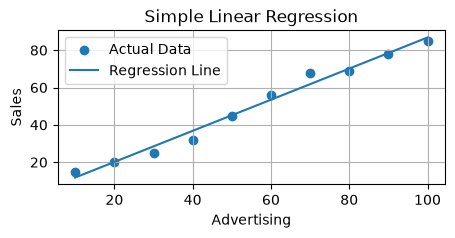

In [27]:
plt.figure(figsize=(5, 2))

plt.scatter(X, Y, label="Actual Data")

plt.plot(
    X,
    manual_predictions,
    label="Regression Line"
)

plt.xlabel("Advertising")
plt.ylabel("Sales")
plt.title("Simple Linear Regression")

plt.legend()
plt.grid(True)

plt.show()